In [61]:
# Terry Chan # 1010156028
# Leon Qian #
# PHY224H1F 2024 Circuits Exercise - Capacitor
# Oct 6, 2024

In [62]:
# Setting up the program
import numpy as np
import pandas as pd
from uncertainties import ufloat
from uncertainties import unumpy as unp
import uncertainties as unc
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [63]:
# Defining the exponential model
def model(t, v0, tau):
    # Exponential decay model
    # v0: initial voltage
    # tau: time constant = RC
    return v0 * np.exp(-t/tau)

In [64]:
# Assigning variables to the resistor and capictor values
R = 100
C = 22e-9
theoretical_tau = R * C

# Oscilloscope measurement data
h_scale = 12.00e-6
h_offset = 2.700e-6
v_scale = 600e-3
v_offset = 2.25000
v_full_scale = 10 * v_scale

vertical_gain_accuracy = 3/100 * v_full_scale
vertical_offset_accuracy = 0.1 * v_scale + 2e-3 + 1/100 * v_offset
vertical_accuracy = .25/100 * v_full_scale

oscilloscope_75_10 = 6.430e-6
drop = (75-10)/75
auto_tau = oscilloscope_75_10 / drop / np.e
print(f"Time constant as measured by the oscilloscope: {auto_tau:.2e}")

Time constant as measured by the oscilloscope: 2.73e-06


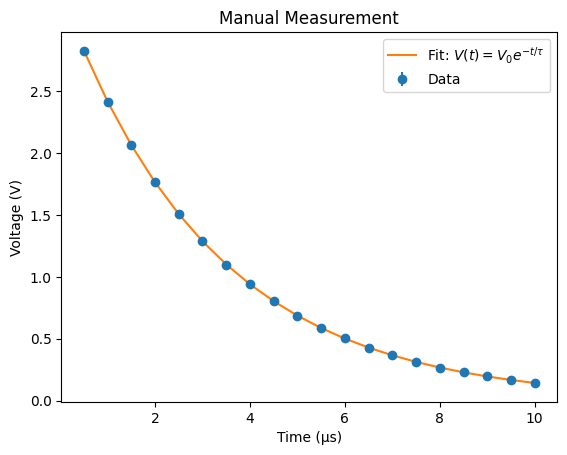

In [65]:
# Analysis of manual measurement data
manual_data = pd.read_csv('oscilloscope_manual.csv')
time = manual_data['Time (μs)']
voltage = unp.uarray(manual_data['Voltage (V)'], vertical_accuracy)

# Fitting the model to the data
popt, pcov = curve_fit(model, time, unp.nominal_values(voltage), sigma=unp.std_devs(voltage), absolute_sigma=True)
v0, manual_tau = popt
v0_err, manual_tau_err = np.sqrt(np.diag(pcov))
v0 = ufloat(v0, v0_err)
manual_tau = ufloat(manual_tau, manual_tau_err)

# Plotting the data and the model
plt.errorbar(time, unp.nominal_values(voltage), yerr=unp.std_devs(voltage), fmt='o', label='Data')
plt.plot(time, model(time, v0.nominal_value, manual_tau.nominal_value), label='Fit: $V(t) = V_0 e^{-t/\\tau}$')
plt.xlabel('Time (μs)')
plt.ylabel('Voltage (V)')
plt.title('Manual Measurement')
plt.legend()
plt.savefig('manual_fit.png')
plt.show()

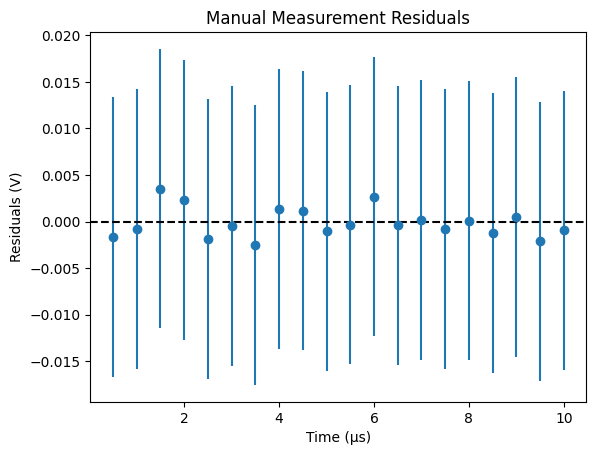

In [66]:
# Plot the residuals
residuals = unp.uarray(unp.nominal_values(voltage) - model(time, v0.nominal_value, manual_tau.nominal_value), vertical_accuracy)
plt.errorbar(time, unp.nominal_values(residuals), yerr=unp.std_devs(residuals), fmt='o')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Time (μs)')
plt.ylabel('Residuals (V)')
plt.title('Manual Measurement Residuals')
plt.savefig('manual_residuals.png')
plt.show()

In [67]:
# Display the results
print(f'tau = ({manual_tau:.3uP}) μs')

# Calculate chi squared
chi_squared = np.sum((unp.nominal_values(residuals) / unp.std_devs(residuals))**2)
dof = len(time) - 2
chi_squared_red = chi_squared / dof
print(f'χ² = {chi_squared:.3f}')
print(f'χ²_red = {chi_squared_red:.3f}')
print(f'v_0 = {v0}')

tau = (3.1775±0.0183) μs
χ² = 0.227
χ²_red = 0.013


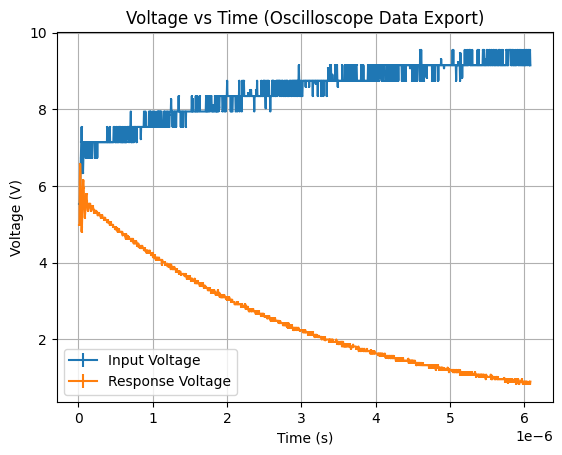

In [68]:
# Oscilloscope data export analysis
# Reading data from the csv file
data = pd.read_csv('oscilloscope_capacitor.csv')
data = data[2:]

# Converting to numeric
data['x-axis'] = pd.to_numeric(data['x-axis'])
data['1'] = pd.to_numeric(data['1'])
data['2'] = pd.to_numeric(data['2'])

# Cleaning up the data
data = data[data['x-axis'] >= 0]
data = data[data['1'] >= 0]
data = data[3:-2]

# Extracting data
time = np.array(data['x-axis'], dtype=np.longdouble)
response = np.array(data['1'], dtype=np.longdouble)
input_voltage = np.array(data['2'], dtype=np.longdouble)

# Calculating the uncertainties
vertical_scale = 1 # V/div
full_scale = 10 # div
vertical_offset = 0 # V

vertical_gain_accuracy = 3/100 * full_scale
vertical_offset_accuracy = 0.1 * vertical_scale + 2e-3 + 1/100 * vertical_offset
vertical_accuracy = .25/100 * full_scale

# Plotting the data
fig, ax = plt.subplots()
ax.errorbar(time, input_voltage, yerr=vertical_accuracy, label='Input Voltage')
ax.errorbar(time, response, yerr=vertical_accuracy, label='Response Voltage')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Voltage (V)')
ax.set_title('Voltage vs Time (Oscilloscope Data Export)')
ax.legend()
ax.grid()
plt.savefig('oscilloscope_data.png')
plt.show()

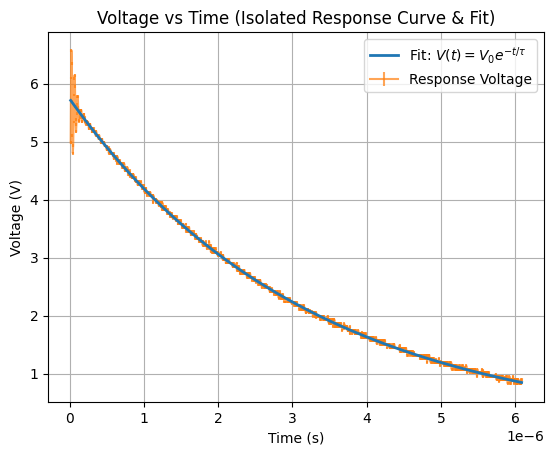

In [69]:
# Fitting the data with the model
popt, pcov = curve_fit(model, time, response, p0=[10, 2.2e-6], sigma=np.full_like(response, vertical_accuracy), absolute_sigma=True)
v0 = ufloat(popt[0], np.sqrt(pcov[0, 0]))
tau = ufloat(popt[1], np.sqrt(pcov[1, 1]))

# Plotting the fitting and data
fig, ax = plt.subplots()
ax.plot(time, model(time, *popt), label='Fit: $V(t) = V_0 e^{-t/\\tau}$', linewidth=2, zorder=100)
ax.errorbar(time, response, yerr=vertical_accuracy, label='Response Voltage', alpha=.7)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Voltage (V)')
ax.set_title('Voltage vs Time (Isolated Response Curve & Fit)')
ax.legend()
ax.grid()
plt.savefig('oscilloscope_fit.png')
plt.show()

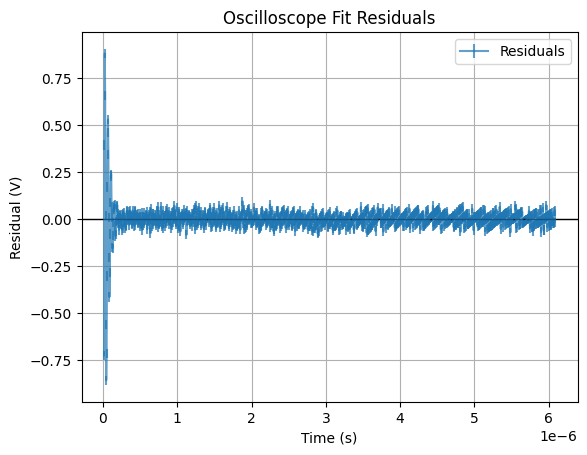

In [70]:
# Plotting the residuals
residuals = response - model(time, *popt)

fig, ax = plt.subplots()
ax.errorbar(time, residuals, yerr=vertical_accuracy, label='Residuals', alpha=.7)
ax.axhline(0, color='black', linewidth=1)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Residual (V)')
ax.set_title('Oscilloscope Fit Residuals')
ax.legend()
ax.grid()
plt.savefig('oscilloscope_residuals.png')
plt.show()

In [71]:
# Calculating chi squared
chi_squared = np.sum((residuals/vertical_accuracy)**2)
dof = len(time) - 2
chi_squared_red = chi_squared / dof

# Printing the data
print(f'v0 = {v0:.2uP}')
print(f'tau = {tau:.2uP}')
print(f'chi^2 = {chi_squared:.2f}')
print(f'chi^2_red = {chi_squared_red:.2f}')

v0 = 5.7408±0.0021
tau = (3.1816±0.0019)×10⁻⁶
chi^2 = 9127.40
chi^2_red = 7.23


In [72]:
print(f"Theoretical time constant: {theoretical_tau*1e6:.2f} μs")
print(f"Time constant as measured by the oscilloscope: {auto_tau*1e6:.2f} μs")
print(f"Time constant as calculated from the manual measurement fit: {manual_tau:.2uP} μs")
print(f"Time constant as calculated from the oscilloscope fit: {tau*1e6:.2uP} μs")

Theoretical time constant: 2.20 μs
Time constant as measured by the oscilloscope: 2.73 μs
Time constant as calculated from the manual measurement fit: 3.178±0.018 μs
Time constant as calculated from the oscilloscope fit: 3.1816±0.0019 μs
